# Exploratory analysis of the Azure VM workload

Purpose: understand the workload behind the two forecasting targets (`active_vm_count` and `aggregate_cpu_utilization`) before modelling, and decide what the models should and should not try to learn.

- Inputs: `vm_cpu_readings.csv.gz` and `vm_metadata.csv.gz` from release `data-v1` (10,000 VMs, 134 readings each, 5-minute sampling).
- Outputs: figures in `reports/figures/eda_*.png` and tables in `reports/tables/eda_*.csv`.
- Run: kernel `atomity`, then `jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb`.
- Scope: every statistic that informs modelling uses only the first 110 timestamps (the training window). The final 24 timestamps are never examined here. Only the data-quality counts in section 1 look at all 134 timestamps.
- Units: CPU values are percentages of one VM's capacity; "pp" means percentage points; one step is 5 minutes.

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cwfc import analysis as an
from cwfc.data import (
    ACTIVE_VM_COUNT,
    AGGREGATE_CPU,
    HOLDOUT_HORIZON,
    INTERVAL_SECONDS,
    SECONDS_PER_DAY,
    SECONDS_PER_HOUR,
    SECONDS_PER_MINUTE,
    STEPS_PER_HOUR,
    build_targets,
    check_readings,
    load_metadata,
    load_readings,
    select_timestamps,
    split_holdout,
)

an.set_plot_style()
pd.options.display.float_format = "{:,.4f}".format

SEED = 0                                   # fixed seed for every random draw
STEP_MINUTES = INTERVAL_SECONDS / SECONDS_PER_MINUTE
STEP_HOURS = INTERVAL_SECONDS / SECONDS_PER_HOUR
HIGH_CPU_LEVEL = 80.0                      # percent; an interval maximum above this counts as high CPU

## 1. Data quality and coverage

What is checked: row counts, duplicates, missing and out-of-range values, regularity of the 5-minute grid, and whether the number of reporting VMs changes over time. These checks use all timestamps; everything after this section uses the training window only.

In [2]:
readings_all = load_readings()
quality = check_readings(readings_all)
display(pd.Series(dataclasses.asdict(quality), name="value").to_frame())

targets_all = build_targets(readings_all)
train_targets, holdout = split_holdout(targets_all)
del holdout, targets_all  # the final 24 timestamps are not examined anywhere below
train_readings = select_timestamps(readings_all, train_targets.index)
del readings_all
metadata = load_metadata()

aggregate = train_targets[AGGREGATE_CPU]
train_hours = an.elapsed_hours(train_targets.index)
print(f"Training window: {len(train_targets)} timestamps, {len(train_targets) * STEP_HOURS:.1f} hours")
print("Distinct time steps in the training window (seconds):", np.unique(np.diff(train_targets.index)).tolist())
print("Readings and metadata describe the same VMs:", set(metadata["vm_id"]) == set(train_readings["vm_id"]))

,value
n_rows,1340000
n_vms,10000
n_timestamps,134
n_duplicate_vm_timestamps,0
n_missing_vm_id,0
n_missing_avg_cpu,0
n_out_of_range_avg_cpu,0
n_irregular_steps,0
sorted_by_timestamp,True
vm_count_is_constant,True


Training window: 110 timestamps, 9.2 hours
Distinct time steps in the training window (seconds): [300]


Readings and metadata describe the same VMs: True


### What the data looks like

The readings table has one row per VM per timestamp. The targets are built by grouping those rows by timestamp: `active_vm_count` is the number of distinct VMs and `aggregate_cpu_utilization` is the mean of their `avg_cpu`. Identifiers are cut to 8 characters for display.

In [3]:
def short_ids(frame):
    """Return a copy of a frame with long identifier columns cut to 8 characters for display."""
    shown = frame.copy()
    for column in ("vm_id", "subscription_id", "deployment_id"):
        if column in shown:
            shown[column] = shown[column].str[:8] + "..."
    return shown


print("Readings (one row per VM per timestamp), first rows:")
display(short_ids(train_readings.head()))
print("Metadata (one row per VM), first rows:")
display(short_ids(metadata.head(3)))

Readings (one row per VM per timestamp), first rows:


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNa...,1.8122,14.5870,4.8517
1,0,pjJUurJZ...,4.1260,5.6509,4.6879
2,0,iiljldVG...,1.2257,2.0821,1.6076
3,0,/f+jE9mr...,1.9396,3.2288,2.3747
4,0,wClSIZ+A...,0.3522,0.8550,0.5975


Metadata (one row per VM), first rows:


,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf...,zidmVREt...,gFCpVCrX...,0,2591400,76.3171,4.7704,8.4918,Delay-insensitive,2,2
1,BH2lz1WP...,JOJ5q+T2...,+qsl6upF...,0,406200,96.7553,0.6996,23.8143,Unknown,8,64
2,vstJO/1L...,0kctkGk3...,TJuS+gMf...,0,2591400,83.1104,5.8788,11.2938,Delay-insensitive,2,4


In [4]:
first = train_readings[train_readings["timestamp"] == train_readings["timestamp"].min()]
print(f"Timestamp {first['timestamp'].iloc[0]}: {len(first):,} rows from {first['vm_id'].nunique():,} distinct VMs, mean avg_cpu = {first['avg_cpu'].mean():.4f}")
print("Targets (one row per timestamp), first rows:")
display(train_targets.head(3))

Timestamp 0: 10,000 rows from 10,000 distinct VMs, mean avg_cpu = 9.3969
Targets (one row per timestamp), first rows:


,active_vm_count,aggregate_cpu_utilization
timestamp,,
0,10000,9.3969
300,10000,9.3538
600,10000,9.4544


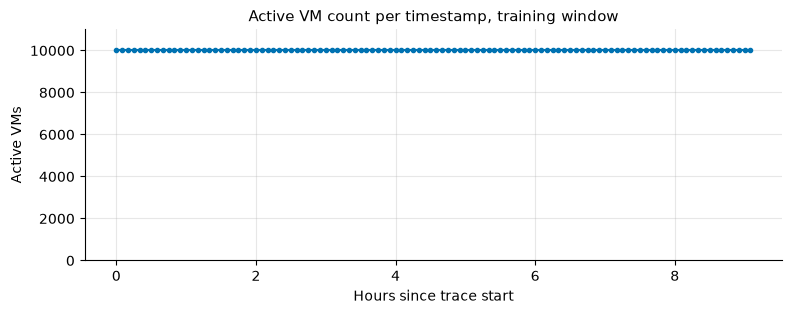

In [5]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(train_hours, train_targets[ACTIVE_VM_COUNT], marker="o", markersize=3)
ax.set(ylim=(0, 1.1 * train_targets[ACTIVE_VM_COUNT].max()), xlabel="Hours since trace start", ylabel="Active VMs", title="Active VM count per timestamp, training window")
an.save_figure(fig, "eda_active_vm_count")
plt.show()

Finding: the release is clean. It has 1,340,000 rows, 10,000 VMs and 134 timestamps on an exact 5-minute grid (every step in the training window is 300 seconds), with no duplicates, no missing ids or values, no out-of-range values and sorted rows. The number of reporting VMs is exactly 10,000 at every timestamp (`eda_active_vm_count.png`), and the readings and the metadata describe the same VMs. The training window is 110 timestamps (9.2 hours).

So what: the number of VMs is always 10,000, so there is nothing to predict for `active_vm_count`: repeating the last value (called a persistence forecast) is always exactly right. All the forecasting effort goes into the CPU series. The data needs no cleaning and no filling-in of missing values.

## 2. Aggregate CPU over time and trend

What is checked: the shape of `aggregate_cpu_utilization` in the training window, its one-hour rolling mean and spread, and whether a straight-line trend is distinguishable from noise.

In [6]:
rolling = aggregate.rolling(STEPS_PER_HOUR)
rolling_mean = rolling.mean()
trend = an.fit_trend(aggregate)
steps = np.arange(len(aggregate))

trend_table = pd.DataFrame(
    {
        "slope_pp_per_hour": [trend.slope * STEPS_PER_HOUR],
        "ci_low_pp_per_hour": [trend.ci_low * STEPS_PER_HOUR],
        "ci_high_pp_per_hour": [trend.ci_high * STEPS_PER_HOUR],
        "p_value": [trend.p_value],
        "r_squared": [trend.r_squared],
        "change_over_2h_pp": [trend.slope * HOLDOUT_HORIZON],
    }
)
hours = lambda timestamp: (timestamp - train_targets.index[0]) / SECONDS_PER_HOUR
series_stats = pd.Series(
    {
        "mean_pct": aggregate.mean(),
        "std_pp": aggregate.std(),
        "min_pct": aggregate.min(),
        "hour_of_min": hours(aggregate.idxmin()),
        "max_pct": aggregate.max(),
        "hour_of_max": hours(aggregate.idxmax()),
        "range_pp": aggregate.max() - aggregate.min(),
        "rolling_mean_max_pct": rolling_mean.max(),
        "hour_of_rolling_mean_max": hours(rolling_mean.idxmax()),
        "last_value_pct": aggregate.iloc[-1],
        "last_value_minus_mean_in_std": (aggregate.iloc[-1] - aggregate.mean()) / aggregate.std(),
    },
    name="value",
).to_frame()
an.save_table(trend_table, "eda_trend")
an.save_table(series_stats, "eda_series_stats")
display(series_stats)
display(trend_table)

,value
mean_pct,9.4141
std_pp,0.1936
min_pct,9.1116
hour_of_min,9.0000
max_pct,9.9122
hour_of_max,4.5833
range_pp,0.8005
rolling_mean_max_pct,9.7895
hour_of_rolling_mean_max,5.5000
last_value_pct,9.1646


,slope_pp_per_hour,ci_low_pp_per_hour,ci_high_pp_per_hour,p_value,r_squared,change_over_2h_pp
0,-0.0127,-0.0264,0.0010,0.0686,0.0304,-0.0254


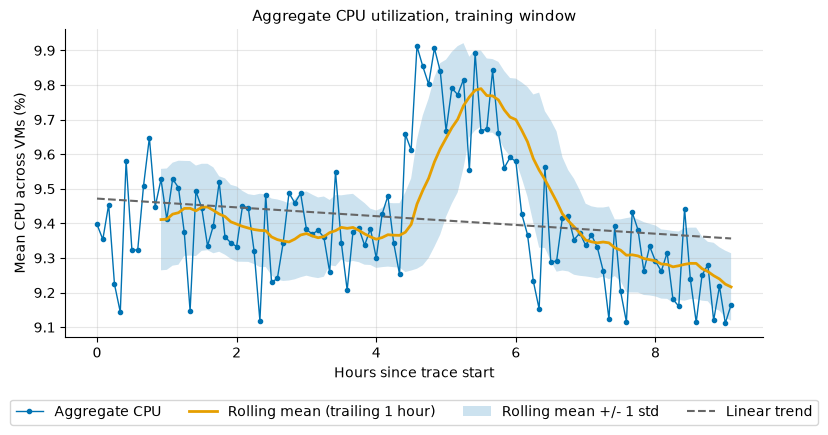

In [7]:
fig, ax = plt.subplots()
ax.plot(train_hours, aggregate, marker="o", markersize=3, linewidth=1, label="Aggregate CPU")
ax.plot(train_hours, rolling_mean, linewidth=2, label="Rolling mean (trailing 1 hour)")
ax.fill_between(train_hours, rolling_mean - rolling.std(), rolling_mean + rolling.std(), alpha=0.2, label="Rolling mean +/- 1 std")
ax.plot(train_hours, trend.intercept + trend.slope * steps, "--", color=an.PALETTE["grey"], label="Linear trend")
ax.set(xlabel="Hours since trace start", ylabel="Mean CPU across VMs (%)", title="Aggregate CPU utilization, training window")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=4)
an.save_figure(fig, "eda_aggregate_series")
plt.show()

Finding: the aggregate averages 9.41% with a standard deviation of 0.19 pp and ranges from 9.11% (hour 9.0) to 9.91% (hour 4.6), a range of 0.80 pp (`eda_aggregate_series.png`, `eda_series_stats.csv`). The trailing one-hour rolling mean peaks at 9.79% at hour 5.5, about 0.4 pp above the series average, and the series ends at 9.16%, 1.3 standard deviations below its mean. The straight-line trend is -0.013 pp per hour (95% interval -0.026 to +0.001, p = 0.07, R-squared 0.03), which is -0.03 pp over two hours.

So what: over a 2-hour window the trend is too small to matter (about -0.03 pp), so the forecast does not need a trend. But the average CPU does not stay constant: for about 1.7 hours (hours 4.4 to 6.1) it sat roughly 0.4 pp above its level outside that period (section 9), so the forecast has to cope with sudden changes in level. The series also ends at a low point (9.16%, below its average of 9.41%), so a forecast that simply repeats the last value would assume the CPU stays low.

## 3. Stationarity

What is checked: whether the mean and variance stay constant over time. The Augmented Dickey-Fuller (ADF) test assumes a unit root (non-stationary) and the Kwiatkowski-Phillips-Schmidt-Shin (KPSS) test assumes stationarity, so they are read together: stationary means ADF rejects (small p) and KPSS does not (large p). Both are run on the level and on the first difference (each value minus the one before).

In [8]:
stationarity = an.stationarity_tests(aggregate)
an.save_table(stationarity, "eda_stationarity")
display(stationarity)

,adf_statistic,adf_p_value,kpss_statistic,kpss_p_value
level,-1.7348,0.4133,0.3075,0.1000
first difference,-2.6808,0.0774,0.1406,0.1000


Finding: the tests do not give a clear answer (`eda_stationarity.csv`). For the level, ADF does not reject a unit root (p = 0.41) and KPSS does not reject stationarity (p of 0.10 or more; the reported value is capped at 0.10). For the first difference, ADF is borderline (p = 0.08) and KPSS again does not reject. With 110 points both tests have little power.

So what: with only 110 points, the tests cannot tell whether the series wanders freely (a random walk, where each value is the previous one plus a random step) or stays around a fixed level. We therefore do not assume either. The modelling stage tries both kinds of model and keeps the one that forecasts better when tested on earlier parts of the training data (called cross-validation). Section 6 gives separate evidence that the series is not a random walk.

## 4. Autocorrelation

What is checked: how strongly each value depends on earlier values (autocorrelation function, ACF) and on earlier values after removing the effect of intermediate lags (partial autocorrelation function, PACF), for the level and for the first difference. Dashed lines mark the 95% band expected for white noise (independent random values). The Ljung-Box test checks whether any autocorrelation up to a given lag is present; a small p-value means the series is not white noise.

In [9]:
MAX_LAG = 30                               # autocorrelation lags computed
LAGS_SHOWN = [1, 2, 3, 10, 11, 12, 24, 25, 30]

band = an.white_noise_band(len(aggregate))
level_ac = an.autocorrelation_table(aggregate, MAX_LAG)
diff_ac = an.autocorrelation_table(aggregate.diff().dropna(), MAX_LAG)
lag_table = pd.DataFrame(
    {
        "level_acf": level_ac["acf"].loc[LAGS_SHOWN],
        "level_pacf": level_ac["pacf"].loc[LAGS_SHOWN],
        "difference_acf": diff_ac["acf"].loc[LAGS_SHOWN],
    }
)
ljung = an.ljung_box(aggregate)
an.save_table(lag_table, "eda_autocorrelation_lags")
an.save_table(ljung, "eda_ljung_box")

print(f"White-noise band: +/-{band:.3f}")
print("Lags where the level ACF is above the band:", list(level_ac.index[1:][level_ac["acf"].iloc[1:] > band]))
print("Lags where the level ACF is below the band:", list(level_ac.index[1:][level_ac["acf"].iloc[1:] < -band]))
print("Lags where the level PACF is outside the band:", list(level_ac.index[1:][level_ac["pacf"].iloc[1:].abs() > band]))
display(lag_table)
display(ljung)

White-noise band: +/-0.187
Lags where the level ACF is above the band: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12]
Lags where the level ACF is below the band: [23, 25, 26, 28, 29, 30]
Lags where the level PACF is outside the band: [1, 2, 3, 7, 8, 11, 12, 13, 25]


,level_acf,level_pacf,difference_acf
lag,,,
1,0.6621,0.6621,-0.4148
2,0.5946,0.2781,-0.1970
3,0.6640,0.3776,0.2425
10,0.2131,-0.1736,-0.1360
11,0.1499,-0.1904,-0.3518
12,0.3274,0.3038,0.6079
24,-0.0199,0.0557,0.5764
25,-0.2263,-0.2787,-0.3164
30,-0.2124,-0.0678,0.1712


,statistic,p_value
lag,,
5,200.3821,0.0000
10,274.8750,0.0000
20,300.9161,0.0000


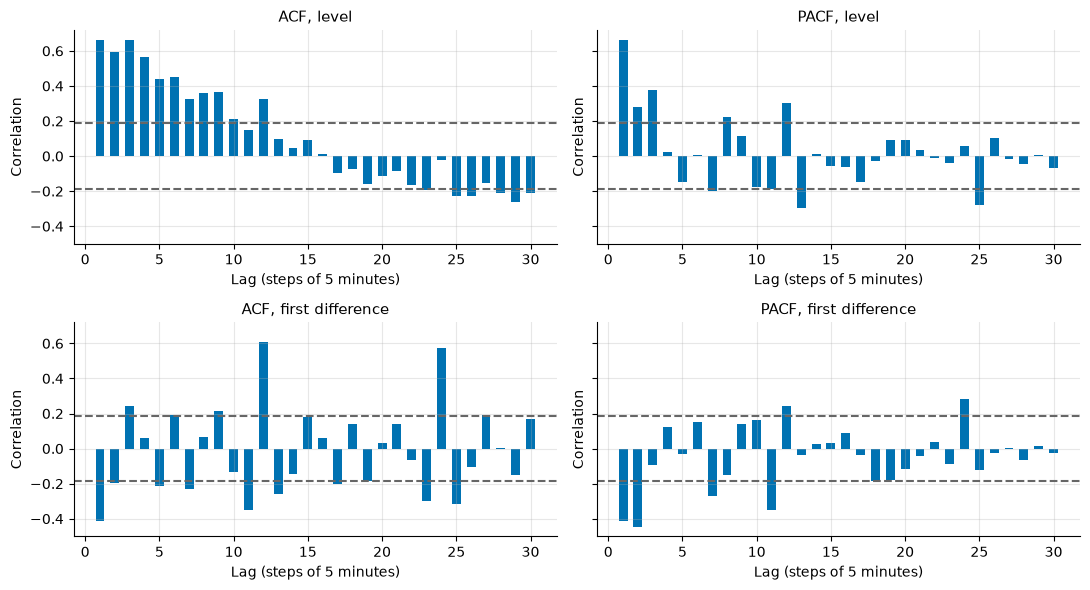

In [10]:
series_by_name = {"Level": level_ac, "First difference": diff_ac}
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for row, (name, table) in enumerate(series_by_name.items()):
    for ax, column, label in zip(axes[row], ["acf", "pacf"], ["ACF", "PACF"]):
        ax.bar(table.index[1:], table[column].iloc[1:], width=0.6)
        ax.axhline(band, linestyle="--", color=an.PALETTE["grey"])
        ax.axhline(-band, linestyle="--", color=an.PALETTE["grey"])
        ax.set(title=f"{label}, {name.lower()}", xlabel="Lag (steps of 5 minutes)", ylabel="Correlation")
fig.tight_layout()
an.save_figure(fig, "eda_autocorrelation")
plt.show()

Finding: the level is strongly autocorrelated: 0.66, 0.59 and 0.66 at lags 1 to 3 (`eda_autocorrelation.png`, `eda_autocorrelation_lags.csv`). The ACF is above the white-noise band (plus or minus 0.19) at lags 1 to 10 and 12 (lag 11 is just below), and below it at lags 23, 25, 26 and 28 to 30 (about -0.2), which reflects the series rising and then falling. The PACF is outside the band at lags 1, 2, 3, 7, 8, 11, 12, 13 and 25, with positive values at lags 1 to 3 (0.66, 0.28, 0.38) and at lag 12 (0.30). The Ljung-Box test rejects white noise at lags 5, 10 and 20 (p below 0.0001). The first difference has a negative lag-1 autocorrelation (-0.41) and large positive values at lags 12 and 24 (0.61 and 0.58).

So what: the CPU at one time is closely related to the CPU over the previous few steps (up to about 50 minutes), so recent values are useful inputs for a forecast. The strongest links are with the last 1 to 3 steps and with the value exactly one hour earlier, so a model using those values is a good starting point. The step-to-step changes tend to swing back and forth (a rise is usually followed by a fall), which suggests modelling the CPU level itself and not its changes; testing will confirm this. The links at 12 and 24 steps point to an hourly pattern, which section 5 examines.

## 5. Cycles and seasonality

What is checked: whether a repeating cycle with a period up to a few hours exists. The periodogram shows power by period. A scan scores how well a repeating pattern of each candidate period explains the series, and the series is folded into one-hour cycles. A seasonal-trend decomposition using LOESS (STL) then separates the trend, the hourly pattern and the remainder. The slow rise and fall in the aggregate would swamp short cycles, so the scan and the folding use the series after removing a centered rolling mean of about one hour. Eleven hours of data cannot reveal daily or weekly cycles, so those are not testable here and are not modelled.

In [11]:
N_TOP_PERIODS = 3                          # largest periodogram peaks listed
DETREND_WINDOW = STEPS_PER_HOUR + 1        # centered rolling mean removed before looking for cycles
CYCLE_SCAN = range(3, HOLDOUT_HORIZON + 1) # candidate periods scored, in steps

periodogram = an.periodogram_table(aggregate, STEP_MINUTES)
top_peaks = periodogram.nlargest(N_TOP_PERIODS, "power").assign(share_of_total_power=lambda d: d["power"] / periodogram["power"].sum())
residual = (aggregate - aggregate.rolling(DETREND_WINDOW, center=True, min_periods=DETREND_WINDOW // 2 + 1).mean()).dropna()
strength = an.cycle_strength(residual, CYCLE_SCAN, INTERVAL_SECONDS)
folded = an.fold_by_period(residual, STEPS_PER_HOUR, INTERVAL_SECONDS)
minutes_in_cycle = folded.columns * STEP_MINUTES

profile = pd.DataFrame({"mean_deviation_pp": folded.mean(), "std_across_hours_pp": folded.std(), "hours_observed": folded.count()})
profile.index = minutes_in_cycle
profile.index.name = "minutes_into_hour"
lowest = profile["mean_deviation_pp"].idxmin()
cycle_summary = pd.Series(
    {
        "strength_at_60_minutes": strength.loc[STEPS_PER_HOUR],
        "rank_of_60_minutes_among_scanned_periods": int(strength.rank(ascending=False).loc[STEPS_PER_HOUR]),
        "scanned_periods": len(strength),
        "strongest_other_period_steps": int(strength.drop(STEPS_PER_HOUR).idxmax()),
        "strongest_other_period_strength": strength.drop(STEPS_PER_HOUR).max(),
        "strongest_period_below_24_steps": int(strength.loc[:HOLDOUT_HORIZON - 1].idxmax()),
        "profile_range_pp": profile["mean_deviation_pp"].max() - profile["mean_deviation_pp"].min(),
        "residual_std_pp": residual.std(),
        "lowest_position_minutes": lowest,
        "lowest_position_deviation_pp": profile.loc[lowest, "mean_deviation_pp"],
        "lowest_position_std_across_hours_pp": profile.loc[lowest, "std_across_hours_pp"],
        "hours_below_zero_at_lowest_position": int((folded[lowest // STEP_MINUTES].dropna() < 0).sum()),
    },
    name="value",
).to_frame()
an.save_table(top_peaks, "eda_periodogram_peaks")
an.save_table(profile, "eda_cycle_profile")
an.save_table(cycle_summary, "eda_cycle_summary")
display(top_peaks)
display(profile)
display(cycle_summary)

,period_minutes,power,share_of_total_power
0,550.0000,1.2337,0.3115
1,275.0000,0.8334,0.2105
2,183.3333,0.2885,0.0728


,mean_deviation_pp,std_across_hours_pp,hours_observed
minutes_into_hour,,,
0.0000,-0.0187,0.0593,10
5.0000,0.0170,0.0491,10
10.0000,0.0199,0.0570,9
15.0000,-0.0849,0.0821,9
20.0000,-0.2112,0.0727,9
25.0000,0.1379,0.0508,9
30.0000,-0.0439,0.0588,9
35.0000,-0.0599,0.1284,9
40.0000,0.0754,0.0792,9


,value
strength_at_60_minutes,0.5929
rank_of_60_minutes_among_scanned_periods,2.0000
scanned_periods,22.0000
strongest_other_period_steps,24.0000
strongest_other_period_strength,0.5977
strongest_period_below_24_steps,12.0000
profile_range_pp,0.3491
residual_std_pp,0.1115
lowest_position_minutes,20.0000
lowest_position_deviation_pp,-0.2112


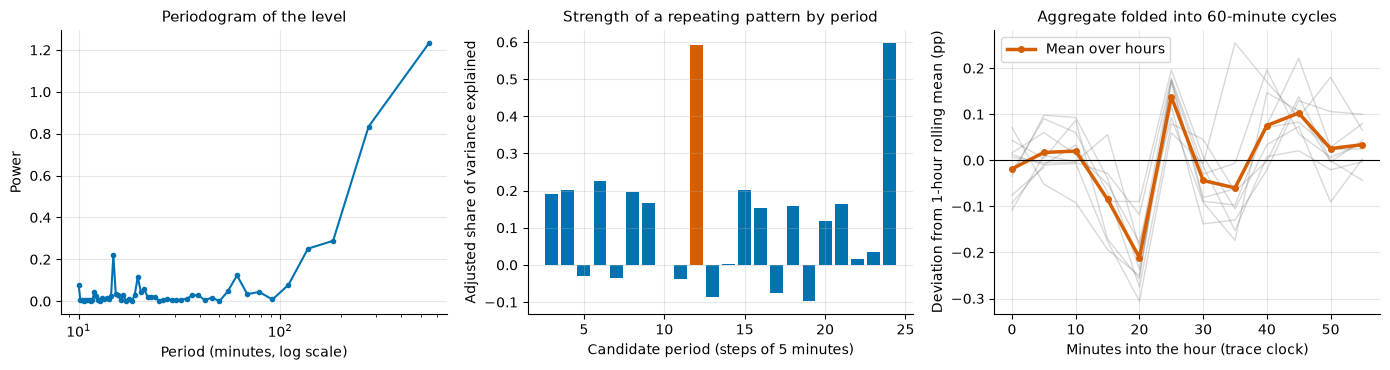

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(periodogram["period_minutes"], periodogram["power"], marker="o", markersize=3)
axes[0].set(xscale="log", xlabel="Period (minutes, log scale)", ylabel="Power", title="Periodogram of the level")
axes[1].bar(strength.index, strength, color=np.where(strength.index == STEPS_PER_HOUR, an.PALETTE["red"], an.PALETTE["blue"]))
axes[1].set(xlabel="Candidate period (steps of 5 minutes)", ylabel="Adjusted share of variance explained", title="Strength of a repeating pattern by period")
for _, cycle in folded.iterrows():
    axes[2].plot(minutes_in_cycle, cycle, color=an.PALETTE["grey"], alpha=0.25, linewidth=1)
axes[2].plot(minutes_in_cycle, folded.mean(), color=an.PALETTE["red"], linewidth=2.5, marker="o", markersize=4, label="Mean over hours")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set(xlabel="Minutes into the hour (trace clock)", ylabel="Deviation from 1-hour rolling mean (pp)", title="Aggregate folded into 60-minute cycles")
axes[2].legend()
fig.tight_layout()
an.save_figure(fig, "eda_cycles")
plt.show()

,value
trend_strength,0.8303
seasonal_strength,0.6134
seasonal_range_pp,0.4320
residual_std_pp,0.0710
trend_range_pp,0.5918


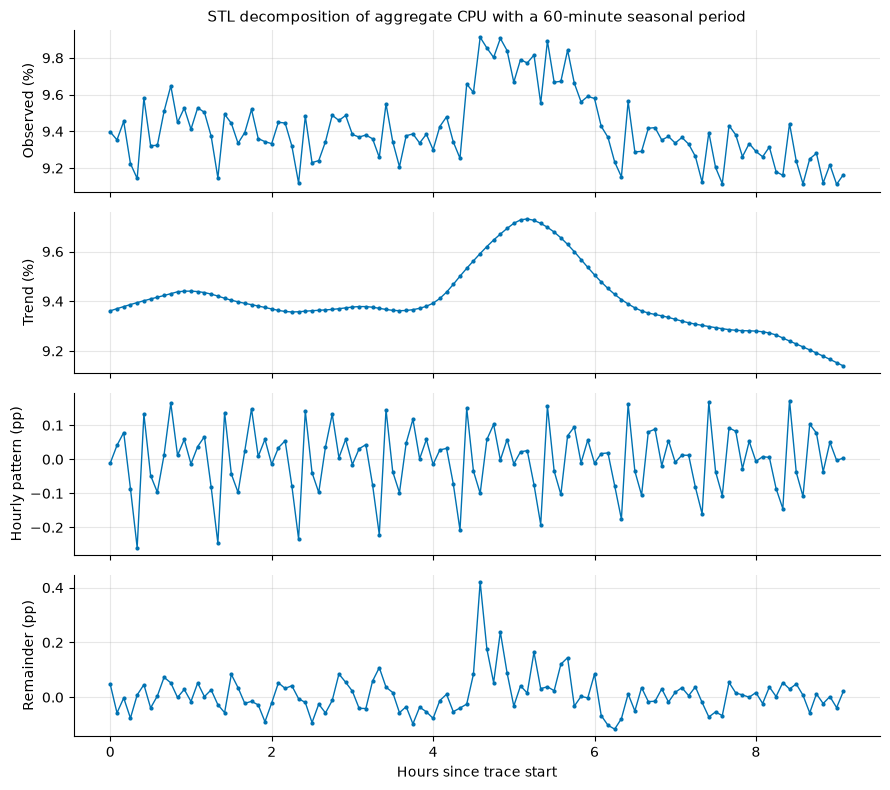

In [13]:
STL_SEASONAL_WINDOW = 13                   # larger keeps the seasonal pattern stable across cycles

components = an.stl_decompose(aggregate, STEPS_PER_HOUR, STL_SEASONAL_WINDOW)
stl_summary = an.stl_strengths(components).to_frame("value")
stl_summary.loc["seasonal_range_pp"] = components["seasonal"].max() - components["seasonal"].min()
stl_summary.loc["residual_std_pp"] = components["resid"].std()
stl_summary.loc["trend_range_pp"] = components["trend"].max() - components["trend"].min()
an.save_table(stl_summary, "eda_stl_summary")
display(stl_summary)

labels = {"observed": "Observed (%)", "trend": "Trend (%)", "seasonal": "Hourly pattern (pp)", "resid": "Remainder (pp)"}
fig, axes = plt.subplots(len(labels), 1, figsize=(9, 8), sharex=True)
for ax, (name, label) in zip(axes, labels.items()):
    ax.plot(train_hours, components[name], marker="o", markersize=2, linewidth=1)
    ax.set_ylabel(label)
axes[0].set_title("STL decomposition of aggregate CPU with a 60-minute seasonal period")
axes[-1].set_xlabel("Hours since trace start")
fig.tight_layout()
an.save_figure(fig, "eda_stl")
plt.show()

Finding: the periodogram of the level is dominated by the longest periods (the 550 and 275 minute components hold 31% and 21% of the power), which reflects the slow rise and fall, so it hides short cycles (`eda_cycles.png`). After removing a one-hour rolling mean, a repeating pattern with a 60-minute period explains 59% of the variance (adjusted), more than any shorter period tested (15 to 115 minutes). The 120-minute period scores about the same (60%) because it contains the 60-minute pattern twice. Folded into hours, the aggregate dips by 0.21 pp at the 20-minute mark in every one of the 9 observed hours and rebounds by 0.14 pp at the 25-minute mark. The pattern spans 0.35 pp from its lowest to its highest minute, about three times the 0.11 pp standard deviation of the detrended series. The lowest minute was picked after looking at the data, but its dip is about three standard deviations from zero across the 9 hours (mean -0.21 pp, standard deviation 0.07 pp), so it is unlikely to be a selection artefact. The STL decomposition (`eda_stl.png`) agrees: the hourly pattern has a seasonal strength of 0.61 and spans 0.43 pp, the trend (strength 0.83) spans 0.59 pp and carries the slow rise and fall, and the remainder has a standard deviation of 0.07 pp.

So what: the CPU follows a repeating one-hour pattern: it dips by about 0.2 pp at the same point of every hour (20 minutes in) and then recovers. That dip is about as large as the usual spread of the whole series (0.19 pp), so a forecast that ignores the pattern will make errors that could be avoided. The position within the hour is known in advance from the timestamp, so a model can use it. Limits: the pattern comes from only 9 hours, we do not know why it happens, and 11 hours of data cannot show whether there are daily or weekly patterns, so none are used.

## 6. Signal versus noise

What is checked: how much the aggregate moves over one step and over the 24-step forecast horizon, whether its variability is constant over time (rolling standard deviation), and how the size of an h-step change grows with h. A change that keeps growing like the square root of h means a random walk, where the latest value is the best guide. A change that levels off near the independent-noise line means the series wanders around a stable level, where an average of recent values is the better guide.

In [14]:
change_std = an.horizon_change_std(aggregate, range(1, HOLDOUT_HORIZON + 1))
level_std = aggregate.std()
one_step = aggregate.diff().dropna()
horizon_change = aggregate.diff(HOLDOUT_HORIZON).dropna()
rolling_std = aggregate.rolling(STEPS_PER_HOUR).std().dropna()

noise_table = pd.Series(
    {
        "level_std_pp": level_std,
        "one_step_change_std_pp": change_std.loc[1],
        "h24_change_std_pp": change_std.loc[HOLDOUT_HORIZON],
        "h24_changes_observed": len(horizon_change),
        "change_std_max_pp": change_std.max(),
        "independent_noise_change_std_pp": np.sqrt(2) * level_std,
        "first_horizon_at_independent_noise_line_steps": int(change_std[change_std >= np.sqrt(2) * level_std].index.min()),
        "random_walk_h24_change_std_pp": change_std.loc[1] * np.sqrt(HOLDOUT_HORIZON),
        "rolling_std_min_pp": rolling_std.min(),
        "rolling_std_max_pp": rolling_std.max(),
        "rolling_std_max_over_min": rolling_std.max() / rolling_std.min(),
        "hour_of_rolling_std_max": (rolling_std.idxmax() - train_targets.index[0]) / SECONDS_PER_HOUR,
    },
    name="value",
).to_frame()
an.save_table(noise_table, "eda_signal_vs_noise")
display(noise_table)

,value
level_std_pp,0.1936
one_step_change_std_pp,0.1580
h24_change_std_pp,0.2851
h24_changes_observed,86.0000
change_std_max_pp,0.3112
independent_noise_change_std_pp,0.2737
first_horizon_at_independent_noise_line_steps,16.0000
random_walk_h24_change_std_pp,0.7742
rolling_std_min_pp,0.0814
rolling_std_max_pp,0.2479


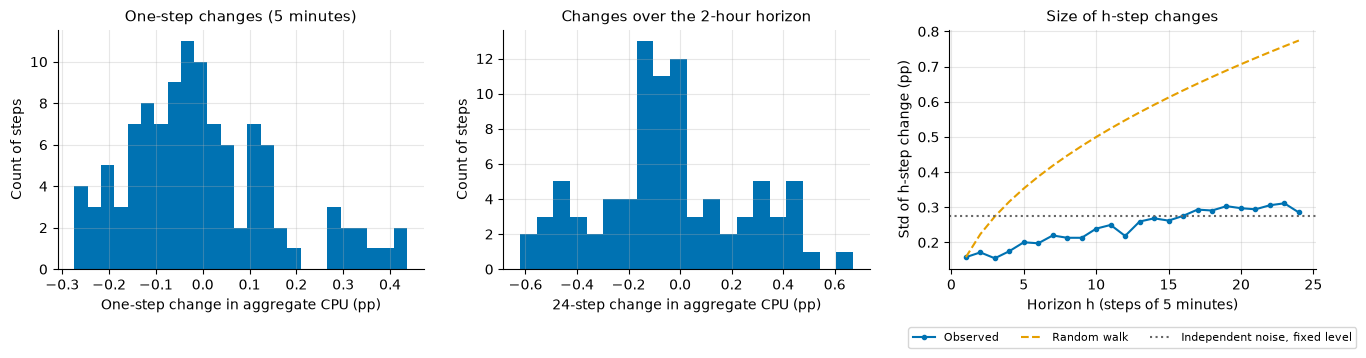

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(one_step, bins=25)
axes[0].set(xlabel="One-step change in aggregate CPU (pp)", ylabel="Count of steps", title="One-step changes (5 minutes)")
axes[1].hist(horizon_change, bins=20)
axes[1].set(xlabel="24-step change in aggregate CPU (pp)", ylabel="Count of steps", title="Changes over the 2-hour horizon")
axes[2].plot(change_std.index, change_std, marker="o", markersize=3, label="Observed")
axes[2].plot(change_std.index, change_std.iloc[0] * np.sqrt(change_std.index), "--", label="Random walk")
axes[2].axhline(np.sqrt(2) * level_std, linestyle=":", color=an.PALETTE["grey"], label="Independent noise, fixed level")
axes[2].set(xlabel="Horizon h (steps of 5 minutes)", ylabel="Std of h-step change (pp)", title="Size of h-step changes")
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=3, fontsize=8)
fig.tight_layout()
an.save_figure(fig, "eda_signal_vs_noise")
plt.show()

Finding: one-step changes are small (standard deviation 0.16 pp, against 0.19 pp for the level), and changes over the 2-hour horizon have a standard deviation of 0.29 pp (86 observed changes; `eda_signal_vs_noise.png`). The standard deviation of h-step changes reaches the independent-noise line (0.27 pp) after 16 steps and peaks at 0.31 pp, far below the random-walk path (0.77 pp at 24 steps). The one-hour rolling standard deviation is not constant: it ranges from 0.08 to 0.25 pp (3.0 times) and is highest at hour 4.9, at the sharp rise.

So what: the CPU does not drift away without limit; it moves around a level. Five minutes ahead the last value is a good guide, but by about an hour ahead it is expected to be no better than simply using the average level (testing will confirm this). Over the 2-hour forecast window, simple forecasts will be wrong by roughly 0.2 to 0.3 pp; how much a better model can reduce that is for the modelling stage to show. The size of the swings also changes over time (about 3 times larger at the sharp rise than in the calmest hour), so the uncertainty range around a forecast should come from the errors seen in testing, not from one fixed number. These errors are small in absolute terms (about 3% of the 9.4% level), so models should be judged by how much they improve on a simple baseline.

## 7. CPU distribution and what drives the aggregate

What is checked: how the individual CPU readings (average, minimum and maximum within each 5-minute interval) are distributed; how CPU load is spread across the 10,000 VMs; how much of the aggregate's movement the highest-variance VMs carry (measured by removing them and recomputing the aggregate); whether VMs move together; and how persistent each VM's own series is. VMs are not selected using the aggregate itself, because that would build correlation into the selection.

In [16]:
IDLE_LEVEL = 5.0                           # percent; a reading or VM below this is near-idle
READING_QUANTILES = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

cpu_readings = train_readings[["min_cpu", "avg_cpu", "max_cpu"]]
reading_quantiles = cpu_readings.quantile(READING_QUANTILES)
reading_quantiles.index = [f"p{round(q * 100)}" for q in READING_QUANTILES]
reading_stats = pd.Series(
    {
        "mean_avg_cpu_pct": cpu_readings["avg_cpu"].mean(),
        "median_avg_cpu_pct": cpu_readings["avg_cpu"].median(),
        "share_of_readings_avg_below_idle_level": (cpu_readings["avg_cpu"] < IDLE_LEVEL).mean(),
        "share_of_readings_avg_above_high_level": (cpu_readings["avg_cpu"] > HIGH_CPU_LEVEL).mean(),
        "share_of_readings_max_above_high_level": (cpu_readings["max_cpu"] > HIGH_CPU_LEVEL).mean(),
        "readings": len(cpu_readings),
    },
    name="value",
).to_frame()
an.save_table(reading_quantiles, "eda_cpu_reading_quantiles")
an.save_table(reading_stats, "eda_cpu_reading_stats")
display(reading_quantiles)
display(reading_stats)

,min_cpu,avg_cpu,max_cpu
p1,0.1077,0.3114,0.5341
p5,0.4060,0.7763,1.4070
p25,1.4911,2.4869,4.4413
p50,3.2292,5.1198,9.1806
p75,5.3322,9.6480,23.8010
p95,22.7698,37.2932,65.7208
p99,78.2578,87.4063,97.5759


,value
mean_avg_cpu_pct,9.4141
median_avg_cpu_pct,5.1198
share_of_readings_avg_below_idle_level,0.4893
share_of_readings_avg_above_high_level,0.0127
share_of_readings_max_above_high_level,0.0295
readings,"1,100,000.0000"


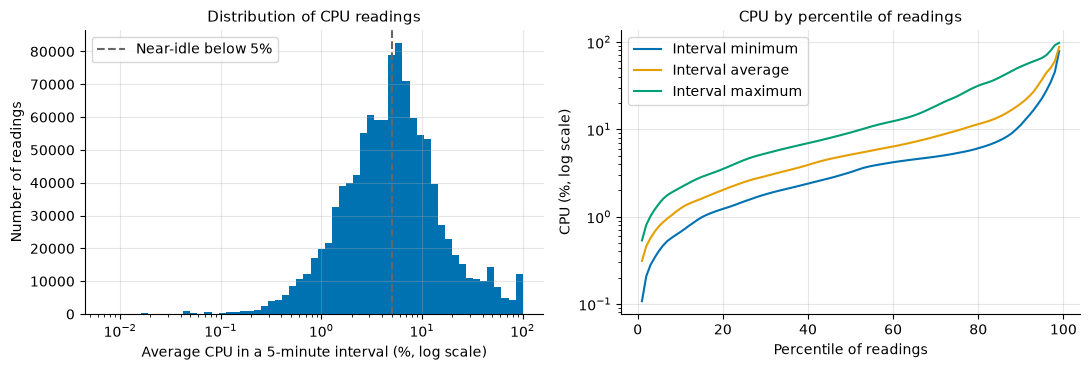

In [17]:
CURVE_LEVELS = np.linspace(0.01, 0.99, 99)

curves = cpu_readings.quantile(CURVE_LEVELS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(cpu_readings["avg_cpu"], bins=np.logspace(np.log10(cpu_readings["avg_cpu"].min()), np.log10(100), 60))
axes[0].axvline(IDLE_LEVEL, linestyle="--", color=an.PALETTE["grey"], label=f"Near-idle below {IDLE_LEVEL:.0f}%")
axes[0].set(xscale="log", xlabel="Average CPU in a 5-minute interval (%, log scale)", ylabel="Number of readings", title="Distribution of CPU readings")
axes[0].legend()
for column, label in (("min_cpu", "Interval minimum"), ("avg_cpu", "Interval average"), ("max_cpu", "Interval maximum")):
    axes[1].plot(CURVE_LEVELS * 100, curves[column], label=label)
axes[1].set(yscale="log", xlabel="Percentile of readings", ylabel="CPU (%, log scale)", title="CPU by percentile of readings")
axes[1].legend()
fig.tight_layout()
an.save_figure(fig, "eda_cpu_readings")
plt.show()

In [18]:
SAMPLE_VMS = 500                           # VMs sampled for pairwise correlations
TOP_VM_SHARE = 0.01
LARGE_VM_SHARE = 0.10
REMOVAL_SHARES = [0, 0.001, 0.005, TOP_VM_SHARE, 0.02, 0.05, LARGE_VM_SHARE, 0.25, 0.50]

wide = an.pivot_readings(train_readings)
n_vms = wide.shape[1]
vm_mean = wide.mean()
decomposition = an.variance_decomposition(wide)
load_curve = an.cumulative_share(vm_mean)
variance_curve = an.cumulative_share(wide.var())
correlations = an.sampled_pairwise_correlations(wide, SAMPLE_VMS, SEED)
implied_correlation = an.implied_average_correlation(wide)
removal = an.aggregate_without_top_variance_vms(wide, REMOVAL_SHARES)
lag1 = an.lag1_autocorrelation(wide).dropna()
independent_std = np.sqrt(wide.var().mean() / n_vms)
top_count = int(TOP_VM_SHARE * n_vms)

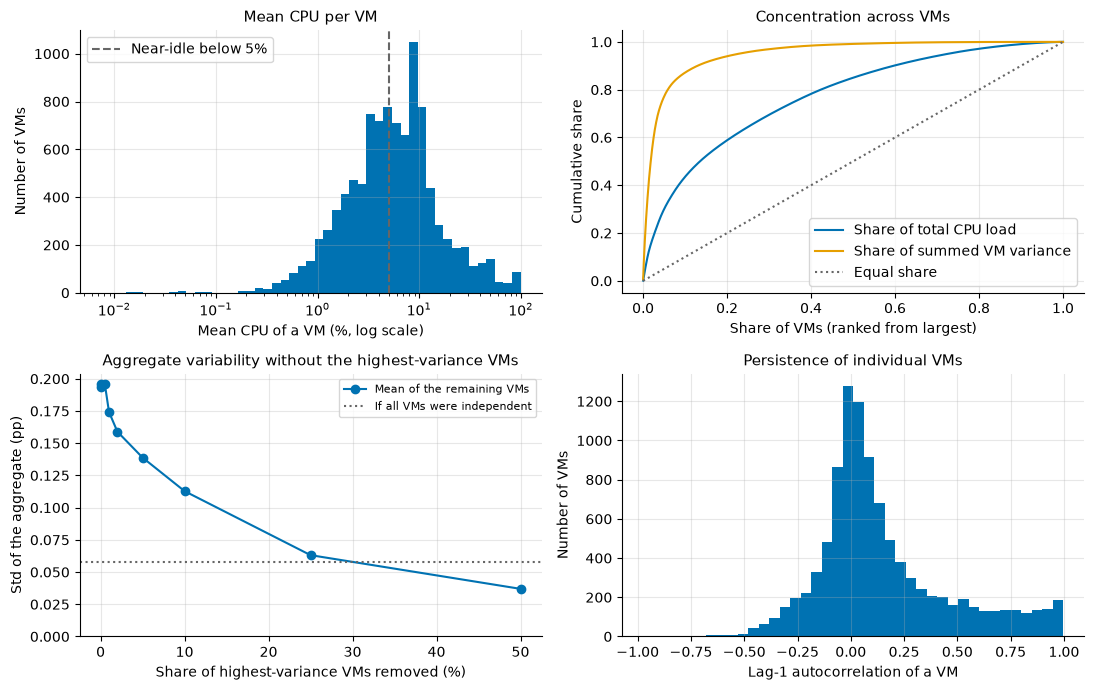

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(vm_mean, bins=np.logspace(np.log10(vm_mean.min()), np.log10(vm_mean.max()), 50))
axes[0, 0].axvline(IDLE_LEVEL, linestyle="--", color=an.PALETTE["grey"], label=f"Near-idle below {IDLE_LEVEL:.0f}%")
axes[0, 0].set(xscale="log", xlabel="Mean CPU of a VM (%, log scale)", ylabel="Number of VMs", title="Mean CPU per VM")
axes[0, 0].legend()
axes[0, 1].plot(load_curve["share_of_items"], load_curve["share_of_total"], label="Share of total CPU load")
axes[0, 1].plot(variance_curve["share_of_items"], variance_curve["share_of_total"], label="Share of summed VM variance")
axes[0, 1].plot([0, 1], [0, 1], ":", color=an.PALETTE["grey"], label="Equal share")
axes[0, 1].set(xlabel="Share of VMs (ranked from largest)", ylabel="Cumulative share", title="Concentration across VMs")
axes[0, 1].legend()
axes[1, 0].plot(removal.index * 100, removal["std"], marker="o", label="Mean of the remaining VMs")
axes[1, 0].axhline(independent_std, linestyle=":", color=an.PALETTE["grey"], label="If all VMs were independent")
axes[1, 0].set(xlabel="Share of highest-variance VMs removed (%)", ylabel="Std of the aggregate (pp)", title="Aggregate variability without the highest-variance VMs")
axes[1, 0].set_ylim(bottom=0)
axes[1, 0].legend(fontsize=8)
axes[1, 1].hist(lag1, bins=40)
axes[1, 1].set(xlabel="Lag-1 autocorrelation of a VM", ylabel="Number of VMs", title="Persistence of individual VMs")
fig.tight_layout()
an.save_figure(fig, "eda_vm_drivers")
plt.show()

In [20]:
BUSY_MEAN_LEVEL = 50.0                     # percent; a VM with higher mean CPU is busy
LAG1_LOW = 0.1                             # a VM with lag-1 autocorrelation below this is barely persistent
LAG1_HIGH = 0.5                            # a VM with lag-1 autocorrelation above this is strongly persistent

drivers = pd.Series(
    {
        "median_vm_mean_cpu_pct": vm_mean.median(),
        "mean_vm_mean_cpu_pct": vm_mean.mean(),
        "share_of_vms_near_idle": (vm_mean < IDLE_LEVEL).mean(),
        "share_of_vms_busy": (vm_mean > BUSY_MEAN_LEVEL).mean(),
        "share_of_load_from_top_1pct_vms": load_curve["share_of_total"].iloc[top_count - 1],
        "share_of_summed_vm_variance_from_top_1pct_vms": variance_curve["share_of_total"].iloc[top_count - 1],
        "between_vm_share_of_value_variance": decomposition["between_vm"] / decomposition["total"],
        "median_vm_lag1_autocorrelation": lag1.median(),
        f"share_of_vms_lag1_below_{LAG1_LOW}": (lag1 < LAG1_LOW).mean(),
        f"share_of_vms_lag1_above_{LAG1_HIGH}": (lag1 > LAG1_HIGH).mean(),
        "mean_pairwise_correlation_random_vms": correlations.mean(),
        "implied_average_correlation_all_vms": implied_correlation,
        "aggregate_std_pp": aggregate.std(),
        "aggregate_std_if_vms_independent_pp": independent_std,
        "aggregate_std_ratio_vs_independent": aggregate.std() / independent_std,
        "aggregate_std_without_top_1pct_vms_pp": removal.loc[TOP_VM_SHARE, "std"],
        "aggregate_std_without_top_10pct_vms_pp": removal.loc[LARGE_VM_SHARE, "std"],
        "aggregate_variance_drop_without_top_1pct_vms": 1 - (removal.loc[TOP_VM_SHARE, "std"] / removal.loc[0, "std"]) ** 2,
        "aggregate_variance_drop_without_top_10pct_vms": 1 - (removal.loc[LARGE_VM_SHARE, "std"] / removal.loc[0, "std"]) ** 2,
    },
    name="value",
).to_frame()
an.save_table(drivers, "eda_vm_drivers")
display(drivers)

,value
median_vm_mean_cpu_pct,5.5017
mean_vm_mean_cpu_pct,9.4141
share_of_vms_near_idle,0.4635
share_of_vms_busy,0.0220
share_of_load_from_top_1pct_vms,0.0960
share_of_summed_vm_variance_from_top_1pct_vms,0.3346
between_vm_share_of_value_variance,0.8358
median_vm_lag1_autocorrelation,0.0618
share_of_vms_lag1_below_0.1,0.5760
share_of_vms_lag1_above_0.5,0.1467


Finding: individual CPU readings are heavily skewed (`eda_cpu_readings.png`, `eda_cpu_reading_quantiles.csv`). The median 5-minute average is 5.1% against a mean of 9.4%, the 95th percentile is 37% and the 99th is 87%; 49% of readings are below 5%, 1.3% have an interval average above 80% and about 3% have an interval maximum above 80%. Interval maxima sit well above averages (median 9.2% against 5.1%; 95th percentile 66% against 37%). Across VMs (`eda_vm_drivers.png`), the median VM averages 5.5% CPU and the mean is 9.4%; 46% of VMs are near-idle (below 5%) and 2.2% average above 50%. The top 1% of VMs carry 9.6% of the load but 33% of the summed VM variance. Most variation is between VMs (84% of the variance of all readings), and a typical VM is hardly persistent from step to step (median lag-1 autocorrelation 0.06; 58% of VMs are below 0.1, but 15% are above 0.5). Random pairs of VMs are essentially uncorrelated (mean 0.003). Yet the aggregate's standard deviation (0.19 pp) is 3.3 times what independent VMs would give (0.06 pp), which implies a tiny positive average correlation of about 0.001 across the fleet; with 10,000 VMs, that small a correlation adds up. Removing the 1% highest-variance VMs lowers the aggregate's standard deviation only from 0.19 to 0.17 pp (19% of its variance), while removing the top 10% lowers it to 0.11 pp (66% of its variance).

So what: most VMs use little CPU and a few use a lot: about half of all readings are below 5%, but 1 reading in 100 is above 87%. Planning capacity from the average alone would miss the busy VMs. The fleet average's movement does not come from a handful of VMs: removing the 1% most variable VMs takes away only 19% of its variation, while removing the 10% most variable takes away about two thirds, so it comes from a large group of highly variable VMs. Their movements are weakly related (average correlation about 0.001), which is enough, across 10,000 VMs, to make the average about 3.3 times more variable than if the VMs were independent. Most individual VMs barely follow their own recent history, so forecasting each VM and adding them up is unlikely to work; we forecast the fleet average directly, as the task asks (per-VM forecasting was not tested). With nearly half of the VMs almost idle, the fleet is lightly used overall, which matters when deciding how much spare capacity to keep.

## 8. VM lifetimes and churn

What is checked: when VMs were created and deleted relative to the observation window. The trace covers 30 days, so deletion times are censored at the trace end: a deletion time equal to the end of the trace is read as still running.

In [21]:
deleted_days = metadata["timestamp_vm_deleted"] / SECONDS_PER_DAY
window_end_days = train_targets.index[-1] / SECONDS_PER_DAY
trace_end_days = deleted_days.max()
lifetimes = pd.Series(
    {
        "vms_created_after_trace_start": int((metadata["timestamp_vm_created"] > 0).sum()),
        "vms_deleted_within_training_window": int((deleted_days <= window_end_days).sum()),
        "earliest_deletion_day": deleted_days.min(),
        "share_alive_at_trace_end": (deleted_days >= trace_end_days).mean(),
        "median_deletion_day": deleted_days.median(),
        "trace_end_day": trace_end_days,
        "training_window_end_day": window_end_days,
    },
    name="value",
).to_frame()
an.save_table(lifetimes, "eda_vm_lifetimes")
display(lifetimes)

,value
vms_created_after_trace_start,0.0000
vms_deleted_within_training_window,0.0000
earliest_deletion_day,0.4688
share_alive_at_trace_end,0.8213
median_deletion_day,29.9931
trace_end_day,29.9931
training_window_end_day,0.3785


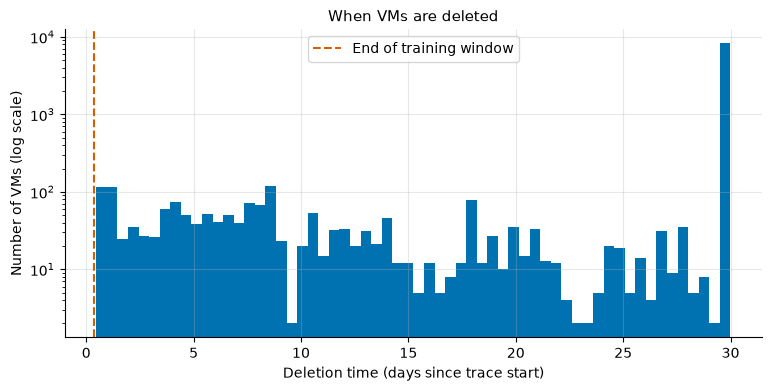

In [22]:
fig, ax = plt.subplots()
ax.hist(deleted_days, bins=60)
ax.axvline(window_end_days, color=an.PALETTE["red"], linestyle="--", label="End of training window")
ax.set(yscale="log", xlabel="Deletion time (days since trace start)", ylabel="Number of VMs (log scale)", title="When VMs are deleted")
ax.legend()
an.save_figure(fig, "eda_vm_lifetimes")
plt.show()

Finding: no VM was created after the start of the trace and none is deleted inside the training window (the earliest deletion is at 0.47 days). 82% of VMs survive to the trace end at day 30; the rest are deleted at a steady trickle between day 0.5 and day 29 (`eda_vm_lifetimes.png`).

So what: no VM is created or deleted during the 9 hours we study, so the number of VMs cannot change and VM churn cannot explain any forecast error. This is partly a result of how the data was chosen: only VMs that ran the whole time are included, so short-lived VMs are missing and real-world churn is understated. Most VMs run for the whole 30-day trace.

## 9. Peaks and low-demand periods

What is checked: when the aggregate is in its top or bottom 20% (thresholds from the training window), how long those periods last, how many VMs reach a high CPU level within an interval, and whether high-load steps come from many VMs shifting a little or from a few VMs rising a lot (comparing each VM's CPU in high-load steps with its CPU in other steps). High-load blocks of at least 30 minutes define the main episode. Capacity is provisioned for peaks, so interval maxima matter as well as means.

In [23]:
PEAK_QUANTILE = 0.80                       # high load: top 20% of training values
LOW_QUANTILE = 0.20                        # low load: bottom 20% of training values
EPISODE_MIN_STEPS = 6                      # high-load blocks of at least 30 minutes form the main episode

high, low = aggregate.quantile(PEAK_QUANTILE), aggregate.quantile(LOW_QUANTILE)
peaks = an.peak_periods(aggregate, high)
lows = an.peak_periods(-aggregate, -low).rename(columns={"maximum": "minimum"})
lows["minimum"] = -lows["minimum"]
start_hours = pd.Series(train_hours, index=train_targets.index)

long_peaks = peaks[peaks["n_steps"] >= EPISODE_MIN_STEPS]
episode_start, episode_end = long_peaks["start"].min(), long_peaks["end"].max()
in_episode = (aggregate.index >= episode_start) & (aggregate.index <= episode_end)
episode = pd.Series(
    {
        "high_load_threshold_pct": high,
        "low_load_threshold_pct": low,
        "episode_start_hour": start_hours[episode_start],
        "episode_end_hour": start_hours[episode_end] + STEP_HOURS,
        "episode_mean_pct": aggregate[in_episode].mean(),
        "outside_episode_mean_pct": aggregate[~in_episode].mean(),
        "episode_rise_pp": aggregate[in_episode].mean() - aggregate[~in_episode].mean(),
    },
    name="value",
).to_frame()

peak_table = pd.concat(
    [
        peaks.assign(kind="high", start_hour=start_hours[peaks["start"]].to_numpy(), duration_minutes=peaks["n_steps"] * STEP_MINUTES),
        lows.assign(kind="low", start_hour=start_hours[lows["start"]].to_numpy(), duration_minutes=lows["n_steps"] * STEP_MINUTES),
    ]
)[["kind", "start_hour", "duration_minutes", "n_steps"]]
an.save_table(episode, "eda_episode")
an.save_table(peak_table, "eda_peak_periods")
display(episode)
display(peak_table)

,value
high_load_threshold_pct,9.5545
low_load_threshold_pct,9.2574
episode_start_hour,4.4167
episode_end_hour,6.0833
episode_mean_pct,9.7325
outside_episode_mean_pct,9.3433
episode_rise_pp,0.3892


,kind,start_hour,duration_minutes,n_steps
0,high,0.4167,5.0000,1
1,high,0.7500,5.0000,1
2,high,4.4167,55.0000,11
3,high,5.4167,40.0000,8
4,high,6.4167,5.0000,1
0,low,0.2500,10.0000,2
1,low,1.3333,5.0000,1
2,low,2.3333,5.0000,1
3,low,2.5000,10.0000,2
4,low,3.5833,5.0000,1


In [24]:
max_wide = an.pivot_readings(train_readings, "max_cpu")
share_high = (max_wide > HIGH_CPU_LEVEL).mean(axis=1)
mean_interval_max = max_wide.mean(axis=1)
peak_stats = pd.Series(
    {
        "share_of_vms_above_high_level_mean": share_high.mean(),
        "share_of_vms_above_high_level_outside_episode_median": share_high[~in_episode].median(),
        "share_of_vms_above_high_level_in_episode_max": share_high[in_episode].max(),
        "mean_interval_max_cpu_pct": mean_interval_max.mean(),
        "correlation_of_aggregate_with_share_above_high_level": aggregate.corr(share_high),
    },
    name="value",
).to_frame()
an.save_table(peak_stats, "eda_peak_stats")
display(peak_stats)

,value
share_of_vms_above_high_level_mean,0.0295
share_of_vms_above_high_level_outside_episode_median,0.0275
share_of_vms_above_high_level_in_episode_max,0.0450
mean_interval_max_cpu_pct,18.4414
correlation_of_aggregate_with_share_above_high_level,0.8237


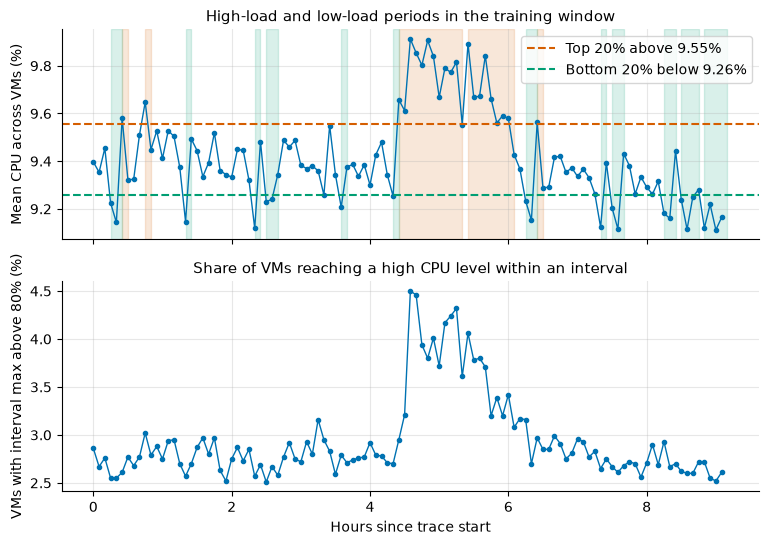

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(train_hours, aggregate, marker="o", markersize=3, linewidth=1)
axes[0].axhline(high, linestyle="--", color=an.PALETTE["red"], label=f"Top 20% above {high:.2f}%")
axes[0].axhline(low, linestyle="--", color=an.PALETTE["green"], label=f"Bottom 20% below {low:.2f}%")
for periods, color in ((peaks, an.PALETTE["red"]), (lows, an.PALETTE["green"])):
    for _, period in periods.iterrows():
        axes[0].axvspan(start_hours[period["start"]], start_hours[period["end"]] + STEP_HOURS, color=color, alpha=0.15)
axes[0].set(ylabel="Mean CPU across VMs (%)", title="High-load and low-load periods in the training window")
axes[0].legend(loc="upper right")
axes[1].plot(train_hours, share_high * 100, marker="o", markersize=3, linewidth=1)
axes[1].set(xlabel="Hours since trace start", ylabel=f"VMs with interval max above {HIGH_CPU_LEVEL:.0f}% (%)", title="Share of VMs reaching a high CPU level within an interval")
an.save_figure(fig, "eda_peaks")
plt.show()

In [26]:
CHANGE_QUANTILES = [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
TOP_RISERS = 100                           # VMs with the largest rise during high-load steps

high_steps = aggregate > high
vm_change = wide.loc[high_steps].mean() - wide.loc[~high_steps].mean()
quantile_shift = (wide.loc[high_steps].stack().quantile(CHANGE_QUANTILES) - wide.loc[~high_steps].stack().quantile(CHANGE_QUANTILES)).rename("shift_pp")
quantile_shift.index = [f"p{round(q * 100)}" for q in CHANGE_QUANTILES]
top_rise = vm_change.nlargest(TOP_RISERS)
tail = pd.Series(
    {
        "high_load_steps": int(high_steps.sum()),
        "aggregate_rise_pp": aggregate[high_steps].mean() - aggregate[~high_steps].mean(),
        "median_vm_change_pp": vm_change.median(),
        "share_of_vms_that_rose": (vm_change > 0).mean(),
        f"share_of_total_rise_from_top_{TOP_RISERS}_vms": top_rise.sum() / vm_change.sum(),
        f"mean_rise_of_top_{TOP_RISERS}_vms_pp": top_rise.mean(),
    },
    name="value",
).to_frame()
an.save_table(quantile_shift, "eda_peak_quantile_shift")
an.save_table(tail, "eda_peak_drivers")
display(quantile_shift.to_frame())
display(tail)

,shift_pp
p10,0.0007
p25,0.0369
p50,0.0719
p75,0.2900
p90,1.5302
p99,1.0750


,value
high_load_steps,22.0000
aggregate_rise_pp,0.3852
median_vm_change_pp,0.0112
share_of_vms_that_rose,0.5202
share_of_total_rise_from_top_100_vms,0.5583
mean_rise_of_top_100_vms_pp,21.5028


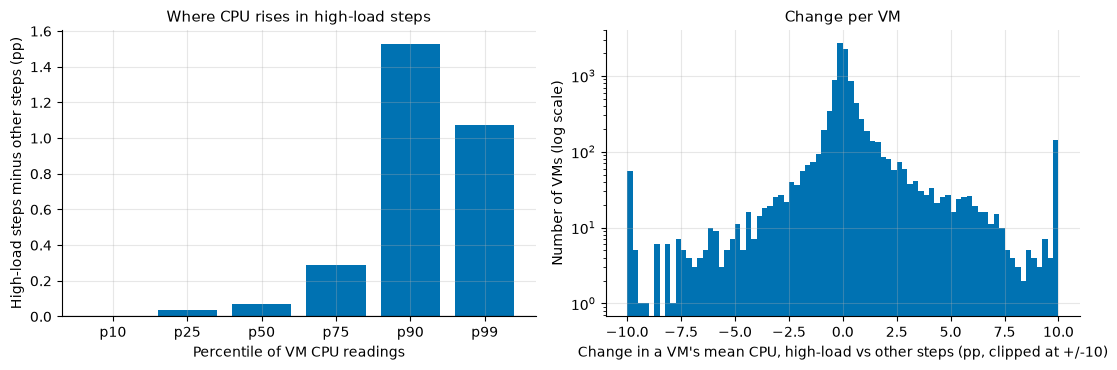

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(quantile_shift.index, quantile_shift.to_numpy())
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="Percentile of VM CPU readings", ylabel="High-load steps minus other steps (pp)", title="Where CPU rises in high-load steps")
axes[1].hist(vm_change.clip(-10, 10), bins=80, log=True)
axes[1].set(xlabel="Change in a VM's mean CPU, high-load vs other steps (pp, clipped at +/-10)", ylabel="Number of VMs (log scale)", title="Change per VM")
fig.tight_layout()
an.save_figure(fig, "eda_peak_drivers")
plt.show()

Finding: the top 20% of training values start at 9.55% and the bottom 20% end at 9.26% (`eda_episode.csv`). The main high-load episode is built from the two blocks of 55 and 40 minutes that start at hours 4.4 and 5.4; it runs from hour 4.4 to 6.1, and the aggregate averages 9.73% in it against 9.34% outside, a rise of 0.39 pp. There are also three isolated single-step excursions. Low load occurs in 12 short runs of 5 to 20 minutes, 5 of them in the last two hours (`eda_peaks.png`). On average 2.95% of VMs (about 295) reach an interval maximum above 80%: 2.75% outside the episode (median) and up to 4.5% inside it; this share correlates 0.82 with the aggregate. The average interval maximum is 18.4% CPU, twice the average (9.4%). Comparing each VM's CPU in the 22 high-load steps (the top 20%) with the other steps, the aggregate is 0.39 pp higher, but the median VM changes by only 0.01 pp and 52% of VMs rose. The rise sits in the upper tail: the 75th percentile of readings rises by 0.29 pp, the 90th by 1.53 pp and the 99th by about 1.1 pp, and the 100 VMs with the largest rise (21.5 pp each on average) account for 56% of the total rise (`eda_peak_drivers.png`).

So what: the high-load periods are short runs of 5 to 55 minutes, and the main episode (two runs back to back) lasted about 1.7 hours. More than half of the increase comes from just 100 VMs (1% of the fleet) that suddenly use much more CPU, while the typical VM stays the same. A 2-hour forecast window can include such an episode, so the forecast has to cope with a sudden rise. The fleet average only rises by about 0.4 pp (from 9.34% to 9.73%), but individual VMs reach much higher CPU for short moments: in about 3% of VM readings the busiest moment of the 5 minutes is above 80%. A capacity plan based only on the average CPU would miss these short, high spikes, so it should also look at the interval maximum (the highest CPU a VM reaches within a 5-minute interval).

## 10. Workload segments

What is checked: how VMs split by category, core count and memory, how much CPU load each segment carries compared with its share of VMs, how variable each segment is (standard deviation over mean of its mean-CPU series), how far its CPU moves over the window, when it peaks, how much it contributes to the rise during the main high-load episode of section 9, and how steady it is over time. The data was sampled in strata by category and core bucket, so the shares describe this sample, not Azure as a whole.

In [28]:
MIN_SEGMENT_VMS = 100                      # smaller segments are too noisy to plot over time
SEGMENTS = {                               # metadata column -> display order of its segments (None: alphabetical)
    "vm_category": None,
    "virtual_core_bucket": ["2", "4", "8", "24", ">24"],
    "memory_gb_bucket": ["2", "4", "8", "32", "64", ">64"],
}

summaries, series_by_segment = {}, {}
for column, order in SEGMENTS.items():
    summary = an.segment_summary(train_readings, metadata, column)
    segment_series = an.segment_series(train_readings, metadata, column)
    if order is not None:
        keep = [label for label in order if label in summary.index]
        summary, segment_series = summary.loc[keep], segment_series[keep]
    first_hour, last_hour = segment_series.iloc[:STEPS_PER_HOUR].mean(), segment_series.iloc[-STEPS_PER_HOUR:].mean()
    summary["relative_variability"] = (segment_series.std() / segment_series.mean()).reindex(summary.index)
    summary["change_first_to_last_hour_pct"] = ((last_hour / first_hour - 1) * 100).reindex(summary.index)
    summary["peak_level_pct_of_mean"] = (segment_series.max() / segment_series.mean() * 100).reindex(summary.index)
    summary["hour_of_peak"] = ((segment_series.idxmax() - train_targets.index[0]) / SECONDS_PER_HOUR).reindex(summary.index)
    episode_change = segment_series[in_episode].mean() - segment_series[~in_episode].mean()
    summary["episode_rise_pct_of_mean"] = (episode_change / segment_series[~in_episode].mean() * 100).reindex(summary.index)
    summary["contribution_to_episode_rise_pp"] = (summary["share_of_vms"] * episode_change).reindex(summary.index)
    summaries[column], series_by_segment[column] = summary, segment_series
    an.save_table(summary, f"eda_segments_{column}")
    display(summary)

,n_vms,mean_cpu_per_vm,share_of_vms,share_of_load,relative_variability,change_first_to_last_hour_pct,peak_level_pct_of_mean,hour_of_peak,episode_rise_pct_of_mean,contribution_to_episode_rise_pp
segment,,,,,,,,,,
Delay-insensitive,6180,8.2573,0.6180,0.5421,0.0263,-1.2020,107.5126,5.1667,5.9413,0.2999
Interactive,3091,11.5051,0.3091,0.3778,0.0212,-0.5447,104.4465,5.4167,2.8795,0.1019
Unknown,729,10.3547,0.0729,0.0802,0.0607,-14.0998,111.6473,1.4167,-1.6625,-0.0126


,n_vms,mean_cpu_per_vm,share_of_vms,share_of_load,relative_variability,change_first_to_last_hour_pct,peak_level_pct_of_mean,hour_of_peak,episode_rise_pct_of_mean,contribution_to_episode_rise_pp
segment,,,,,,,,,,
2,7534,9.7642,0.7534,0.7814,0.0250,-1.0699,106.9100,4.5833,5.4733,0.3987
4,1908,7.9187,0.1908,0.1605,0.0234,-4.3757,105.4194,1.4167,-0.4206,-0.0064
8,486,9.6584,0.0486,0.0499,0.0436,-8.6825,115.2699,0.7500,-0.4237,-0.0020
24,62,11.4288,0.0062,0.0075,0.0358,-7.9519,110.7925,4.4167,-1.0822,-0.0008
>24,10,6.6195,0.0010,0.0007,0.3026,3.8203,222.7041,6.4167,-4.8025,-0.0003


,n_vms,mean_cpu_per_vm,share_of_vms,share_of_load,relative_variability,change_first_to_last_hour_pct,peak_level_pct_of_mean,hour_of_peak,episode_rise_pct_of_mean,contribution_to_episode_rise_pp
segment,,,,,,,,,,
2,3904,8.8023,0.3904,0.3650,0.0254,-1.4601,109.8030,4.6667,5.1033,0.1738
4,2475,11.4595,0.2475,0.3013,0.0308,-1.8908,108.5043,5.6667,5.8592,0.1644
8,2146,9.1434,0.2146,0.2084,0.0309,0.0535,106.2518,0.7500,3.2129,0.0627
32,1383,7.8140,0.1383,0.1148,0.0330,-8.7486,108.9955,0.6667,-0.6842,-0.0074
64,82,11.2172,0.0082,0.0098,0.0428,7.4601,113.1287,8.6667,-4.2192,-0.0039
>64,10,6.6195,0.0010,0.0007,0.3026,3.8203,222.7041,6.4167,-4.8025,-0.0003


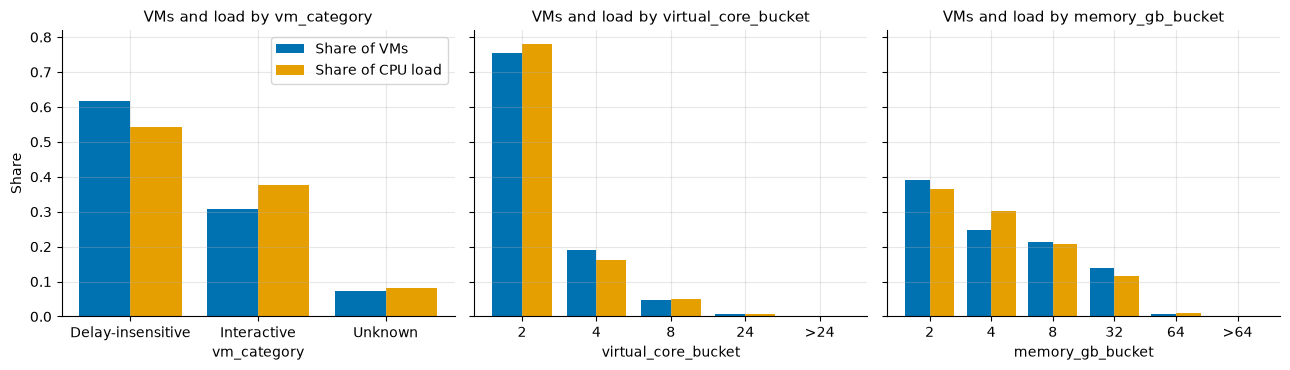

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (column, summary) in zip(axes, summaries.items()):
    positions = np.arange(len(summary))
    ax.bar(positions - 0.2, summary["share_of_vms"], width=0.4, label="Share of VMs")
    ax.bar(positions + 0.2, summary["share_of_load"], width=0.4, label="Share of CPU load")
    ax.set_xticks(positions, summary.index)
    ax.set(xlabel=column, title=f"VMs and load by {column}")
axes[0].set_ylabel("Share")
axes[0].legend()
fig.tight_layout()
an.save_figure(fig, "eda_segments_shares")
plt.show()

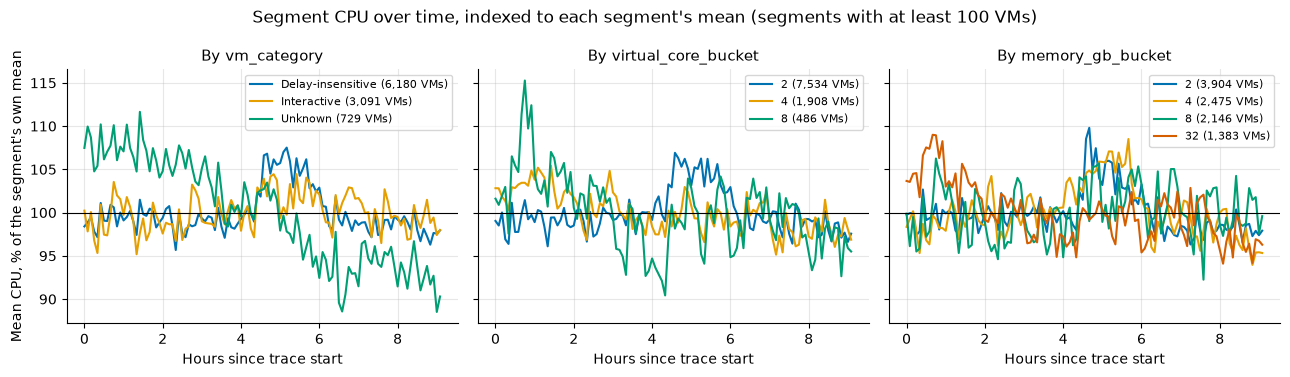

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, (column, segment_series) in zip(axes, series_by_segment.items()):
    large = [label for label in segment_series.columns if summaries[column].loc[label, "n_vms"] >= MIN_SEGMENT_VMS]
    for label in large:
        ax.plot(train_hours, segment_series[label] / segment_series[label].mean() * 100, label=f"{label} ({summaries[column].loc[label, 'n_vms']:,} VMs)")
    ax.axhline(100, color="black", linewidth=0.8)
    ax.set(xlabel="Hours since trace start", title=f"By {column}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean CPU, % of the segment's own mean")
fig.suptitle(f"Segment CPU over time, indexed to each segment's mean (segments with at least {MIN_SEGMENT_VMS} VMs)")
fig.tight_layout()
an.save_figure(fig, "eda_segments_series")
plt.show()

Finding: by category, Delay-insensitive VMs are 62% of VMs and 54% of load (mean 8.3% CPU), Interactive VMs are 31% of VMs but 38% of load (mean 11.5%), and Unknown VMs are 7% and 8% (`eda_segments_shares.png`). By cores, 2-core VMs are 75% of VMs and 78% of load; by memory, 2 GB VMs are 39% of VMs and 36.5% of load (`eda_segments_vm_category.csv` and the two matching files for cores and memory). Of the 0.39 pp rise in the main episode, Delay-insensitive VMs contribute 0.30 pp (77%), Interactive VMs 0.10 pp (26%) and Unknown VMs -0.01 pp. Delay-insensitive VMs peak at 108% of their own mean at hour 5.2 and Interactive VMs at 104% at hour 5.4, whereas Unknown VMs peak at 112% at hour 1.4, before the episode, and then fall 14% from the first to the last hour (`eda_segments_series.png`). Among core buckets, 2-core VMs contribute 0.40 pp of the rise and every other bucket about zero. Segments with at least 100 VMs vary by 2% to 6% (standard deviation over mean); the 10-VM segments vary by 30%.

So what: most of the rise in the main high-load period (section 9) came from Delay-insensitive VMs (77% of it), with Interactive VMs adding about a quarter. A VM's category never changes, so the recent average CPU of each category can be used as an extra input to the forecast. Forecasting very small groups is not worthwhile because they are too noisy (the groups of 10 VMs vary by 30%). These shares count CPU percentage, not CPU cores, and the data was sampled in groups (strata) by category and core size, so they describe this sample and not Azure as a whole.

## Summary of findings

1. Target series and data quality (section 1, `eda_active_vm_count.png`): 1,340,000 rows, 134 timestamps on an exact 300-second grid, and no duplicate, missing or out-of-range values. `active_vm_count` is constant at 10,000. Implication: a persistence forecast is exact for this target, so it needs no model and only absolute errors can be reported; the modelling effort goes to `aggregate_cpu_utilization`.
2. Level, trend and the main episode (sections 2 and 9, `eda_aggregate_series.png`, `eda_series_stats.csv`, `eda_episode.csv`): the mean is 9.41% (standard deviation 0.19 pp, range 9.11% to 9.91%) and the linear trend is -0.013 pp per hour (p = 0.07), or -0.03 pp over the 2-hour horizon. There is a level shift: hours 4.4 to 6.1 average 9.73% against 9.34% outside, +0.39 pp. Implication: no trend component, a model that can adapt to level shifts, and cross-validation origins that include the episode.
3. Stationarity (section 3, `eda_stationarity.csv`): ADF does not reject a unit root on the level (p = 0.41) and KPSS does not reject stationarity (p of 0.10 or more), so with 110 points the tests are inconclusive. Implication: do not assume either; compare differenced and undifferenced specifications in cross-validation.
4. Autocorrelation (section 4, `eda_autocorrelation.png`, `eda_autocorrelation_lags.csv`): the ACF is 0.66 at lag 1 and above the white-noise band at lags 1 to 10 and 12; the PACF is significant at lags 1 to 3 (0.66, 0.28, 0.38) and 12; the first difference has a lag-1 ACF of -0.41, a sign of over-differencing. Implication: autoregressive terms of order about 3 plus a lag-12 term, modelled on the level (d = 0); lags 1 to 3 and 12 as features for a regression model.
5. Hourly seasonality (section 5, `eda_cycles.png`, `eda_stl.png`): a 60-minute pattern explains 59% of the variance of the detrended series, the STL seasonal strength is 0.61 (trend strength 0.83), and the series dips 0.21 pp at the 20-minute mark in 9 of 9 hours. Implication: a seasonal component with period 12, or a position-in-hour feature, which is known at the forecast origin from the timestamp. Caution: only 9 cycles, the cause is unknown, and daily or weekly seasonality cannot be assessed.
6. Signal versus noise (section 6, `eda_signal_vs_noise.png`): the standard deviation of h-step changes levels off (0.27 pp after 16 steps, 0.29 pp at 24 steps) instead of growing like a random walk (0.77 pp), and the one-hour rolling standard deviation varies 3.0 times. Implication: the series is mean-reverting, so persistence is expected to lose its edge within about an hour (to be tested), naive forecasts will miss by roughly 0.2 to 0.3 pp at 2 hours, and the variance is not constant, so prediction intervals should come from cross-validation residuals.
7. Cross-section of VMs (section 7, `eda_cpu_readings.png`, `eda_vm_drivers.png`): readings are heavily right-skewed (median 5.1% against a mean of 9.4%, 99th percentile 87%, 49% below 5%). The aggregate is 3.3 times more variable than independent VMs would give (implied average correlation about 0.001), and this is not concentrated in a few VMs: dropping the 1% highest-variance VMs removes 19% of its variance, the top 10% removes 66%. Most VMs have little autocorrelation of their own (median lag-1 0.06). Implication: forecast the aggregate directly, since bottom-up per-VM forecasts are unlikely to help; the heavy upper tail means capacity planned from the mean would miss the busy VMs.
8. Lifetimes and churn (section 8, `eda_vm_lifetimes.png`): no VM is created or deleted inside the window, and 82% run for the whole 30-day trace. Implication: churn cannot explain forecast errors here, although the complete-trace sampling understates real churn.
9. Peaks (section 9, `eda_peaks.png`, `eda_peak_drivers.png`): high-load runs last 5 to 55 minutes and the main episode about 1.7 hours. 100 VMs account for 56% of the rise while the median VM is unchanged, the mean interval maximum is 18.4% (twice the mean), and about 3% of readings have an interval maximum above 80%. Implication: a 2-hour window can contain such an episode, and capacity advice based on the mean alone would miss the short spikes, so it should also use interval maxima.
10. Segments (section 10, `eda_segments_shares.png`, `eda_segments_series.png`): Delay-insensitive VMs contribute 0.30 of the 0.39 pp episode rise (77%) and Interactive VMs 0.10 pp (26%); Unknown VMs fall 14% over the window; the two 10-VM segments have a coefficient of variation of 30%. Implication: the recent category-level mean can be an extra feature, very small segments should not be forecast, and the shares describe this stratified sample (in CPU percentage, not cores), not Azure.

### Decisions carried into modelling

- `active_vm_count`: persistence, with absolute errors only, because a baseline with zero error leaves no relative improvement to report.
- Baseline for `aggregate_cpu_utilization`: the training-window mean plus the average hourly profile. It captures the level (sections 2 and 6) and the hourly pattern (section 5) without fitted dynamics, so it is expected to be hard to beat (to be confirmed in testing). Persistence is reported as a reference at short horizons (section 6).
- Statistical model: ARIMA-family with d = 0 as the primary specification (sections 3 and 4; d = 1 only as a check in cross-validation) and an autoregressive order of about 3 (section 4), with the hourly pattern as a seasonal component or regressors (section 5). ETS (level and additive seasonality, no trend) is the alternative.
- Machine learning model: regularised regression (ridge) or gradient boosting on engineered features: lags 1 to 3 and 12, a one-hour rolling mean, the most recent change and the position in the hour (sections 4 and 5), and optionally the recent category-level mean (section 10).
- Evaluation: rolling-origin cross-validation on the 110 training points with 24-step forecasts; MAE, RMSE and relative improvement over the baseline, error at selected horizons, and error in high-load periods (threshold from each fold's training history, 9.55% on the full training window); origins must include the main episode (sections 2 and 9).
- Model and feature choices are made on the cross-validation results only; the final 24 timestamps are used once, at the end, to report the result.
- Forecast the aggregate directly (section 7). Prediction intervals come from cross-validation residuals (section 6), and capacity advice also considers interval maxima (section 9).

### Limitations

- Only 110 training points (9.2 hours) and 9 hourly cycles. Daily and weekly seasonality cannot be assessed, and the stability of the hourly pattern cannot be checked beyond this window.
- One trace from one release. The causes of the main episode and of the hourly pattern are unknown.
- ADF and KPSS have little power at this length.
- Only complete traces were eligible, so there is no churn and short-lived VMs are missing. The stratified sampling means segment shares do not represent Azure.
- CPU is analysed as a percentage of each VM's capacity, not weighted by cores.
- The episode and the hourly pattern were found in the training window and are not validated out of sample here.
- The thresholds (top and bottom 20%, episodes of at least 30 minutes) are analyst choices, so the episode boundaries depend on them.
- The explanations in the findings, such as the rise being driven by Delay-insensitive VMs, are descriptive, not causal.